In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [50]:
df = pd.read_csv('automobile_dataset.csv')
df.columns = df.columns.str.strip()

In [51]:
df.head()

,Make,Model,Year,Fuel_Type,Transmission,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Service_History,Color,Body_Type,Drivetrain,Fuel_Efficiency,Location,Selling_Price
0,Mercedes-Benz,GLE,2024,Petrol,Automatic,2.3,100,186.0,196.0,1,0.0,,Silver,SUV,AWD,30.0,IL,64140
1,Hyundai,Tucson,2008,Petrol,Automatic,2.3,387035,189.0,190.0,4,0.0,,Blue,SUV,FWD,35.0,FL,500
2,Volkswagen,Golf,2021,Hybrid,,1.9,46054,158.0,153.0,1,0.0,Partial Service,Gray,Hatchback,AWD,43.0,NY,16429
3,Chevrolet,Tahoe,2005,Petrol,,2.2,141302,169.0,165.0,5,1.0,No Service,Blue,SUV,AWD,,FL,2199
4,Toyota,Camry,2022,Petrol,Automatic,1.9,32813,149.0,141.0,1,0.0,Full Service,Brown,Sedan,FWD,38.0,CA,21792


---

## 4. Data Preprocessing

### 4.1 Memeriksa Missing Value dan Duplikasi Data

In [52]:
print("--- Jumlah Missing Value per Kolom ---")
print(df.isnull().sum())
print("\n--- Jumlah Duplikasi Data ---")
print(df.duplicated().sum())

--- Jumlah Missing Value per Kolom ---
Make                0
Model               0
Year                0
Fuel_Type           0
Transmission        0
Engine_Size         0
Mileage             0
Horsepower          0
Torque              0
Owners              0
Accident_History    0
Service_History     0
Color               0
Body_Type           0
Drivetrain          0
Fuel_Efficiency     0
Location            0
Selling_Price       0
dtype: int64

--- Jumlah Duplikasi Data ---
0


### 4.2 Menghapus Kolom Make, Model, dan Location & Mengimputasi Kolom yang Memiliki Missing Value

In [53]:
df = df.drop(columns=['Make', 'Model', 'Location'])

kolom_numerik = ['Engine_Size', 'Horsepower', 'Torque', 'Fuel_Efficiency', 'Accident_History']
for kol in kolom_numerik:
    df[kol] = pd.to_numeric(df[kol], errors='coerce')

df['Transmission'] = df['Transmission'].fillna(df['Transmission'].mode()[0])
df['Engine_Size'] = df['Engine_Size'].fillna(df['Engine_Size'].median())
df['Horsepower'] = df['Horsepower'].fillna(df['Horsepower'].median())
df['Torque'] = df['Torque'].fillna(df['Torque'].median())
df['Accident_History'] = df['Accident_History'].fillna(0)  # Imputasi kosong dengan 0
df['Service_History'] = df['Service_History'].fillna('No Service')
df['Color'] = df['Color'].fillna(df['Color'].mode()[0])
df['Fuel_Efficiency'] = df['Fuel_Efficiency'].fillna(df['Fuel_Efficiency'].median())

print("Total Missing Value setelah imputasi:", df.isnull().sum().sum())

Total Missing Value setelah imputasi: 0


### 4.3 Mengubah Teks Kategori Menjadi Angka Unik & Memisahkan Fitur Kategorikal pada Kolom Fuel_Type, Body_Type, dan Drivetrain

In [54]:
df['Transmission'] = pd.factorize(df['Transmission'])[0]
df['Service_History'] = pd.factorize(df['Service_History'])[0]
df['Color'] = pd.factorize(df['Color'])[0]

df = pd.get_dummies(df, columns=['Fuel_Type', 'Body_Type', 'Drivetrain'], drop_first=True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Year                    5500 non-null   int64  
 1   Transmission            5500 non-null   int64  
 2   Engine_Size             5500 non-null   float64
 3   Mileage                 5500 non-null   int64  
 4   Horsepower              5500 non-null   float64
 5   Torque                  5500 non-null   float64
 6   Owners                  5500 non-null   int64  
 7   Accident_History        5500 non-null   float64
 8   Service_History         5500 non-null   int64  
 9   Color                   5500 non-null   int64  
 10  Fuel_Efficiency         5500 non-null   float64
 11  Selling_Price           5500 non-null   int64  
 12  Fuel_Type_ Electric     5500 non-null   bool   
 13  Fuel_Type_ Hybrid       5500 non-null   bool   
 14  Fuel_Type_ Petrol       5500 non-null   bool   
 15

### 4.4 Membuat Label Target Baru

In [55]:
conditions = [
    df['Selling_Price'] <= 5000,
    (df['Selling_Price'] > 5000) & (df['Selling_Price'] <= 20000),
    df['Selling_Price'] > 20000
]

choices = ['Low', 'Medium', 'High']

df['Price_Category'] = np.select(conditions, choices, default='')

print("--- Menampilkan 5 Data Teratas ---\n", df[['Selling_Price', 'Price_Category']].head())
print("\n --- Jumlah Frekuensi ---\n", df['Price_Category'].value_counts())

--- Menampilkan 5 Data Teratas ---
    Selling_Price Price_Category
0          64140           High
1            500            Low
2          16429         Medium
3           2199            Low
4          21792           High

 --- Jumlah Frekuensi ---
 Price_Category
Medium    2125
Low       2091
High      1284
Name: count, dtype: int64


### 4.5 Mendeteksi dan Menangani Outlier (IQR dan Z-Score)

In [56]:
Q1 = df['Selling_Price'].quantile(0.25)
Q3 = df['Selling_Price'].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier_awal = ((df['Selling_Price'] < batas_bawah) | (df['Selling_Price'] > batas_atas)).sum()
df['Selling_Price'] = np.clip(df['Selling_Price'], batas_bawah, batas_atas)
outlier_akhir = ((df['Selling_Price'] < batas_bawah) | (df['Selling_Price'] > batas_atas)).sum()

print(f"Outlier Awal: {outlier_awal} -> Sisa Outlier: {outlier_akhir}")


Outlier Awal: 144 -> Sisa Outlier: 0


### 4.6 Feature Scaling Menggunakan Standardization

In [57]:
features = ['Year', 'Engine_Size', 'Mileage', 'Horsepower', 'Torque', 'Owners', 'Fuel_Efficiency']

df[features] = df[features].fillna(df[features].median())

mean = df[features].mean()
std = df[features].std()
df[features] = (df[features] - mean) / std

print(df[features].describe())

               Year   Engine_Size       Mileage    Horsepower        Torque  \
count  5.500000e+03  5.500000e+03  5.500000e+03  5.500000e+03  5.500000e+03   
mean   1.476249e-14  3.533335e-16  1.162706e-17  2.596711e-16  1.408167e-16   
std    1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00   
min   -1.639796e+00 -3.145301e+00 -1.245709e+00 -1.929480e+00 -2.103160e+00   
25%   -9.489191e-01 -4.414429e-01 -8.210140e-01 -6.121931e-01 -5.983796e-01   
50%   -8.532327e-02 -5.517743e-02 -1.916306e-01 -1.860121e-01 -1.793269e-01   
75%    9.509918e-01  4.598432e-01  6.338851e-01  5.113748e-01  4.683001e-01   
max    1.641868e+00  4.193742e+00  4.596194e+00  4.598837e+00  4.868354e+00   

             Owners  Fuel_Efficiency  
count  5.500000e+03     5.500000e+03  
mean   6.911643e-17    -3.552714e-17  
std    1.000000e+00     1.000000e+00  
min   -1.143730e+00    -1.707704e+00  
25%   -1.143730e+00    -4.196857e-01  
50%   -3.624938e-01    -1.334595e-01  
75%    4.187428

### 4.7 Membagi Data Uji dan Data Latih (80%:20%)

In [58]:
X = df.drop(columns=['Selling_Price', 'Price_Category'])
y = df['Selling_Price']

print(f"Bentuk X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"Bentuk Y : {len(y)} label")

np.random.seed(43)
index = np.random.permutation(len(X))
batas = int(0.8 * len(X))

X_train = X.iloc[index[:batas]]
X_test = X.iloc[index[batas:]]
y_train = y.iloc[index[:batas]]
y_test = y.iloc[index[batas:]]

print(f"Data Latih  : {len(X_train)} baris (80%)")
print(f"Data Uji    : {len(X_test)} baris (20%)")

Bentuk X : 5500 baris, 21 kolom
Bentuk Y : 5500 label
Data Latih  : 4400 baris (80%)
Data Uji    : 1100 baris (20%)


---

## 5. Modelling Multiple Linear Regression

### 5.1 Menambahkan Kolom Intercept

In [64]:
def tambah_kolom_bias(x):
    return np.c_[np.ones(x.shape[0]), x].astype(float)

X_train_b = tambah_kolom_bias(X_train)
X_test_b = tambah_kolom_bias(X_test)

y_train = pd.to_numeric(y_train, errors='coerce')
y_test = pd.to_numeric(y_test, errors='coerce')

### 5.2 Melakukan Pelatihan Model Menggunakan Normal Equation (OLS)

In [65]:
beta = np.linalg.inv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train

print("--- Hasil Pelatihan Model Multiple Linear Regression ---")
print(f"Intercept (Beta 0)      : {beta[0]:,.2f} USD")
print("-" * 50)

for index, koefisien in enumerate(beta[1:], start=1):
    print(f"Koefisien Fitur ke-{index}  : {koefisien:,.2f}")

--- Hasil Pelatihan Model Multiple Linear Regression ---
Intercept (Beta 0)      : 9,345.68 USD
--------------------------------------------------
Koefisien Fitur ke-1  : 8,035.89
Koefisien Fitur ke-2  : 623.52
Koefisien Fitur ke-3  : -150.53
Koefisien Fitur ke-4  : -2,108.28
Koefisien Fitur ke-5  : -278.85
Koefisien Fitur ke-6  : 310.90
Koefisien Fitur ke-7  : -111.31
Koefisien Fitur ke-8  : -1,914.88
Koefisien Fitur ke-9  : 210.98
Koefisien Fitur ke-10  : 12.92
Koefisien Fitur ke-11  : 223.13
Koefisien Fitur ke-12  : -1,846.80
Koefisien Fitur ke-13  : -147.23
Koefisien Fitur ke-14  : 235.64
Koefisien Fitur ke-15  : -1,873.87
Koefisien Fitur ke-16  : 4,497.02
Koefisien Fitur ke-17  : 2,154.42
Koefisien Fitur ke-18  : 2,533.24
Koefisien Fitur ke-19  : -353.17
Koefisien Fitur ke-20  : -720.73
Koefisien Fitur ke-21  : -548.41


### 5.3 Melakukan Prediksi pada Data Latih dan Data Uji & Menampilkan Tabel Perbandingan

In [ ]:
y_pred_train = X_train_b @ beta
y_pred_test = X_test_b @ beta

tabel_hasil_prediksi = pd.DataFrame({'Harga Aktual (USD)': y_test.values[:5], 'Harga Prediksi (USD)': y_pred_test[:5]
})

print("\n--- Contoh 5 Prediksi Harga Mobil Bekas pada Data Uji ---")
print(tabel_hasil_prediksi.to_string(index=False, formatters={'Harga Aktual (USD)': '{:,.2f}'.format, 'Harga Prediksi (USD)': '{:,.2f}'.format
}))


--- Contoh 5 Prediksi Harga Mobil Bekas pada Data Uji ---
Harga Aktual (USD) Harga Prediksi (USD)
         20,357.00            19,418.99
         15,210.00            21,107.09
         26,219.00            28,000.82
         30,397.00            22,594.20
         45,786.62            27,532.07


---

## 6. Evaluation

### 6.1 

In [70]:
r2 = 1 - (np.sum((y_test - y_pred_test) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))
mse = np.mean((y_test - y_pred_test) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(y_test - y_pred_test))

print("--- Hasil Evaluasi Model ---")
print(f"R-Squared   : {r2:.4f}")
print(f"MSE         : {mse:,.2f}")
print(f"RMSE        : {rmse:,.2f} USD")
print(f"MAE         : {mae:,.2f} USD")

--- Hasil Evaluasi Model ---
R-Squared   : 0.7078
MSE         : 44,385,626.71
RMSE        : 6,662.25 USD
MAE         : 5,208.28 USD


In [72]:
r2_train = 1 - (np.sum((y_train - y_pred_train) ** 2) / np.sum((y_train - np.mean(y_train)) ** 2))
mse_train = np.mean((y_train - y_pred_train) ** 2)
rmse_train = np.sqrt(mse_train)
mae_train = np.mean(np.abs(y_train - y_pred_train))

r2_test = 1 - (np.sum((y_test - y_pred_test) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))
mse_test = np.mean((y_test - y_pred_test) ** 2)
rmse_test = np.sqrt(mse_test)
mae_test = np.mean(np.abs(y_test - y_pred_test))

tabel_evaluasi = pd.DataFrame({
    'Metrik Evaluasi': ['R-Squared (R2)', 'MSE', 'RMSE (USD)', 'MAE (USD)'],
    'Data Latih': [r2_train, mse_train, rmse_train, mae_train],
    'Data Uji': [r2_test, mse_test, rmse_test, mae_test]
})

print("--- Perbandingan Evaluasi Model ---")
print(tabel_evaluasi.to_string(index=False, formatters={
    'Data Latih (Train)': lambda x: f"{x:,.4f}" if x < 1 else f"{x:,.2f}",
    'Data Uji (Test)': lambda x: f"{x:,.4f}" if x < 1 else f"{x:,.2f}"
}))

--- Perbandingan Evaluasi Model ---
Metrik Evaluasi   Data Latih     Data Uji
 R-Squared (R2) 7.103316e-01 7.077700e-01
            MSE 4.161966e+07 4.438563e+07
     RMSE (USD) 6.451330e+03 6.662254e+03
      MAE (USD) 5.064473e+03 5.208277e+03


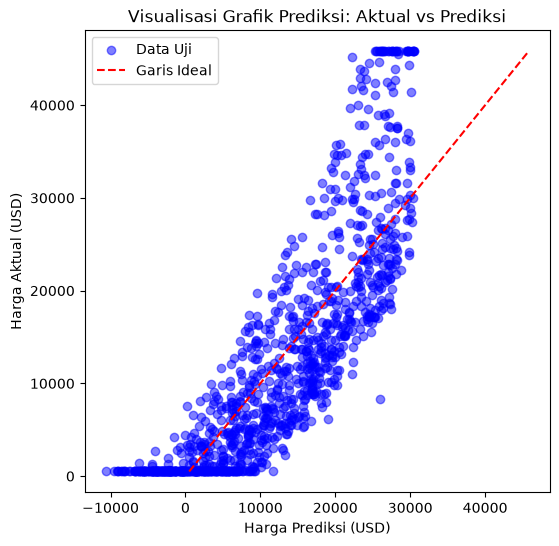

In [73]:
plt.figure(figsize=(6, 6))
plt.scatter(y_pred_test, y_test, color='blue', alpha=0.5, label='Data Uji')

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', label='Garis Ideal')

plt.xlabel('Harga Prediksi (USD)')
plt.ylabel('Harga Aktual (USD)')
plt.title('Visualisasi Grafik Prediksi: Aktual vs Prediksi')
plt.legend()

plt.show()